In [2]:
!pip install -q mlflow scikit-learn pandas numpy matplotlib seaborn joblib

import os
import joblib
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create folders for clean organization
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("screenshots", exist_ok=True)

# 1. Data Acquisition (Simulated Real-World Retail Customer Churn Dataset)
np.random.seed(42)
n_samples = 1000

df = pd.DataFrame({
    "customer_id": [f"CUST_{1000+i}" for i in range(n_samples)],
    "age": np.random.randint(18, 65, n_samples),
    "tenure_months": np.random.randint(1, 60, n_samples),
    "monthly_spend": np.round(np.random.uniform(500, 15000, n_samples), 2),
    "support_tickets": np.random.poisson(1.8, n_samples),
    "city": np.random.choice(["Delhi", "Mumbai", "Bengaluru", "Hyderabad", "Pune"], n_samples),
    "segment": np.random.choice(["Bronze", "Silver", "Gold", "Platinum"], n_samples, p=[0.4, 0.3, 0.2, 0.1]),
})

# Inject realistic missing values & duplicates for cleaning demonstration
df.loc[np.random.choice(df.index, 25, replace=False), "monthly_spend"] = np.nan
df.loc[np.random.choice(df.index, 15, replace=False), "city"] = np.nan
df = pd.concat([df, df.iloc[:10]], ignore_index=True)  # Add 10 duplicate rows

# Create target variable: churn (1 = Churned, 0 = Retained)
churn_prob = (
    0.15
    + 0.25 * (df["support_tickets"] > 2).astype(int)
    + 0.20 * (df["tenure_months"] < 12).astype(int)
    - 0.15 * (df["segment"].isin(["Gold", "Platinum"])).astype(int)
)
df["churn"] = (np.random.rand(len(df)) < np.clip(churn_prob, 0.05, 0.90)).astype(int)

df.to_csv("data/raw_data.csv", index=False)
print("Raw Dataset Shape:", df.shape)
df.head()

Raw Dataset Shape: (1010, 8)


,customer_id,age,tenure_months,monthly_spend,support_tickets,city,segment,churn
0,CUST_1000,56,13,7078.56,2,Mumbai,Silver,0
1,CUST_1001,46,40,8190.14,2,Pune,Bronze,0
2,CUST_1002,32,2,759.00,3,Hyderabad,Silver,1
3,CUST_1003,60,20,12053.57,1,Hyderabad,Bronze,0
4,CUST_1004,25,1,4765.44,1,Mumbai,Silver,0


In [3]:
# 2. Data Validation & Cleaning
print("--- Missing Values Before Cleaning ---")
print(df.isnull().sum())
print("\nDuplicate Rows Found:", df.duplicated().sum())

# Remove duplicates and drop identifier column
df_clean = df.drop_duplicates().drop(columns=["customer_id"]).copy()

# Validate numeric ranges
df_clean = df_clean[df_clean["age"] >= 18]

print("\nCleaned Dataset Shape:", df_clean.shape)
print("Data Validation Passed Successfully!")

--- Missing Values Before Cleaning ---
customer_id         0
age                 0
tenure_months       0
monthly_spend      25
support_tickets     0
city               15
segment             0
churn               0
dtype: int64

Duplicate Rows Found: 4

Cleaned Dataset Shape: (1006, 7)
Data Validation Passed Successfully!


/tmp/ipykernel_1829/744726178.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="churn", y="monthly_spend", palette="Set2", ax=axes[0, 1])
/tmp/ipykernel_1829/744726178.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_spend.index, y=city_spend.values, palette="Blues_d", ax=axes[1, 0])


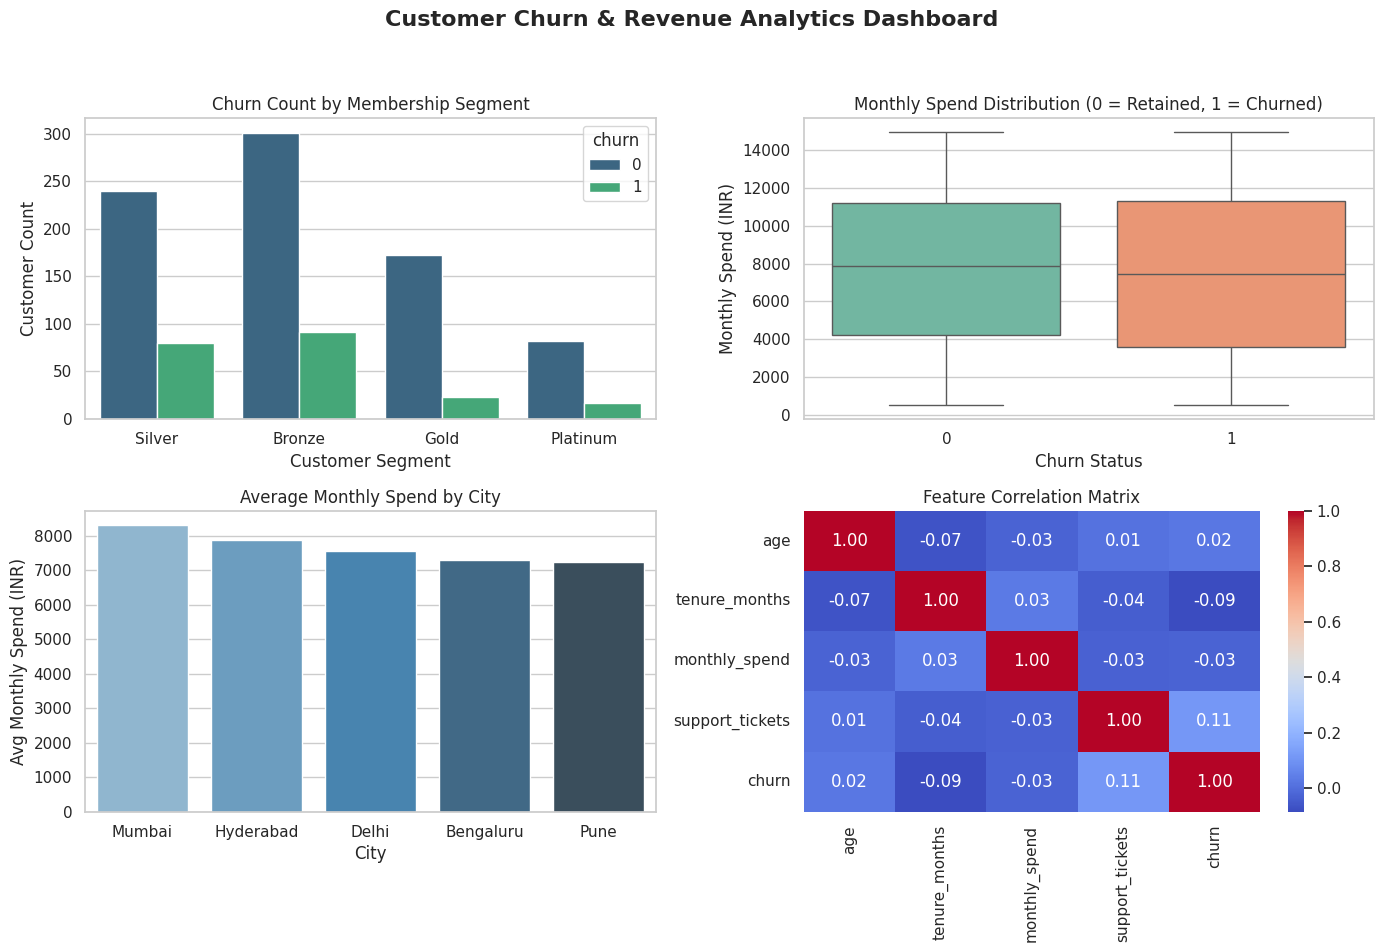

In [4]:
# 3. EDA & Visual Analytics Dashboards
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Customer Churn & Revenue Analytics Dashboard", fontsize=16, fontweight="bold")

# Chart 1: Churn Distribution by Customer Segment
sns.countplot(data=df_clean, x="segment", hue="churn", palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Churn Count by Membership Segment")
axes[0, 0].set_xlabel("Customer Segment")
axes[0, 0].set_ylabel("Customer Count")

# Chart 2: Monthly Spend Distribution by Churn Status
sns.boxplot(data=df_clean, x="churn", y="monthly_spend", palette="Set2", ax=axes[0, 1])
axes[0, 1].set_title("Monthly Spend Distribution (0 = Retained, 1 = Churned)")
axes[0, 1].set_xlabel("Churn Status")
axes[0, 1].set_ylabel("Monthly Spend (INR)")

# Chart 3: City-wise Average Monthly Spend
city_spend = df_clean.groupby("city")["monthly_spend"].mean().sort_values(ascending=False)
sns.barplot(x=city_spend.index, y=city_spend.values, palette="Blues_d", ax=axes[1, 0])
axes[1, 0].set_title("Average Monthly Spend by City")
axes[1, 0].set_xlabel("City")
axes[1, 0].set_ylabel("Avg Monthly Spend (INR)")

# Chart 4: Correlation Heatmap of Numerical Features
num_cols_corr = ["age", "tenure_months", "monthly_spend", "support_tickets", "churn"]
sns.heatmap(df_clean[num_cols_corr].corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title("Feature Correlation Matrix")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("screenshots/analytics_dashboard.png", dpi=300)
plt.show()

In [5]:
# 4. Feature Engineering & Reusable Preprocessing Pipeline
# Create engineered features
df_clean["spend_per_month_tenure"] = df_clean["monthly_spend"] / (df_clean["tenure_months"] + 1)
df_clean["high_ticket_flag"] = (df_clean["support_tickets"] >= 3).astype(int)

X = df_clean.drop(columns=["churn"])
y = df_clean["churn"]

numeric_features = ["age", "tenure_months", "monthly_spend", "support_tickets", "spend_per_month_tenure", "high_ticket_flag"]
categorical_features = ["city", "segment"]

num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipeline, numeric_features),
    ("cat", cat_pipeline, categorical_features)
])

# Full Reusable ML Pipeline (Preprocessing + Feature Selection + Classifier)
full_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("feature_selection", SelectKBest(score_func=f_classif, k=10)),
    ("classifier", RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42))
])

# Export ML-Ready Transformed Dataset
X_transformed = preprocessor.fit_transform(X)
encoded_cat_names = preprocessor.named_transformers_["cat"]["encoder"].get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(encoded_cat_names)

ml_ready_df = pd.DataFrame(X_transformed, columns=all_feature_names)
ml_ready_df["churn"] = y.values
ml_ready_df.to_csv("data/ml_ready_data.csv", index=False)
print("ML-Ready Dataset Exported! Shape:", ml_ready_df.shape)

ML-Ready Dataset Exported! Shape: (1006, 16)


In [6]:
# 5. Experiment Tracking (MLflow), Export & Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

mlflow.set_experiment("Retail_Churn_Capstone_Experiment")

with mlflow.start_run(run_name="RandomForest_Pipeline_v1"):
    full_pipeline.fit(X_train, y_train)
    y_pred = full_pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    # Log parameters & metrics to MLflow
    mlflow.log_param("model_type", "RandomForestClassifier")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("k_best_features", 10)
    mlflow.log_metric("test_accuracy", acc)

    # Export model pipeline
    model_path = "models/trained_pipeline.pkl"
    joblib.dump(full_pipeline, model_path)
    mlflow.log_artifact(model_path)

    print(f"MLflow Run Logged Successfully | Test Accuracy: {acc:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 6. Testing Reloaded Pipeline on Unseen Sample Data
loaded_model = joblib.load("models/trained_pipeline.pkl")
sample_test = X_test.iloc[:5].copy()
sample_preds = loaded_model.predict(sample_test)
sample_probs = loaded_model.predict_proba(sample_test)[:, 1]

sample_test["Predicted_Churn"] = sample_preds
sample_test["Churn_Probability"] = np.round(sample_probs, 3)
print("\n--- Pipeline Reload & Inference Test Passed ---")
sample_test

2026/11/26 09:18:13 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/26 09:18:13 INFO mlflow.store.db.utils: Updating database tables
2026/11/26 09:18:20 INFO mlflow.tracking.fluent: Experiment with name 'Retail_Churn_Capstone_Experiment' does not exist. Creating a new experiment.


MLflow Run Logged Successfully | Test Accuracy: 0.7871

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.99      0.88       160
           1       0.33      0.02      0.04        42

    accuracy                           0.79       202
   macro avg       0.56      0.51      0.46       202
weighted avg       0.70      0.79      0.71       202


--- Pipeline Reload & Inference Test Passed ---


,age,tenure_months,monthly_spend,support_tickets,city,segment,spend_per_month_tenure,high_ticket_flag,Predicted_Churn,Churn_Probability
205,19,47,14690.15,1,Mumbai,Silver,306.044792,0,0,0.174
248,57,50,8412.46,1,Pune,Bronze,164.950196,0,0,0.136
989,30,44,1435.12,0,Delhi,Gold,31.891556,0,0,0.142
716,27,20,7694.41,0,Hyderabad,Bronze,366.400476,0,0,0.115
281,25,19,2911.81,1,Bengaluru,Bronze,145.590500,0,0,0.089
